In [364]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from cvxopt import matrix, solvers
import math
import matplotlib.pyplot as plt
from utils import *
from class_utils import *
from scipy.spatial.distance import cdist 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from collections import defaultdict
from random import sample
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from tqdm import trange, tqdm

from scipy import stats

In [365]:
df_spectra_bg = pd.read_csv('OPTIR/Background Classifications/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2_background_user_classified.csv')
df_spectra_nbg = pd.read_csv('OPTIR/Background Classifications/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2_not_background_user_classification.csv')

df_spectra_bg.columns = ['id'] + list(df_spectra_bg.columns[1:])
df_spectra_bg = df_spectra_bg.set_index('id').T

df_spectra_nbg.columns = ['id'] + list(df_spectra_nbg.columns[1:])
df_spectra_nbg = df_spectra_nbg.set_index('id').T

df_spectra_bg['background'] = 1
df_spectra_nbg['background'] = 0

df_spectra = pd.concat([df_spectra_nbg, df_spectra_bg]).reset_index(drop=True)
x = df_spectra.iloc[:,:-1].to_numpy()
y = df_spectra.iloc[:,-1].to_numpy()

x_ = (x - x.mean(1)[:,None]) / x.std(1)[:,None]

In [362]:
df_spectra_bg.shape#.sum()

(37, 612)

In [363]:
df_spectra_nbg.shape

(76, 612)

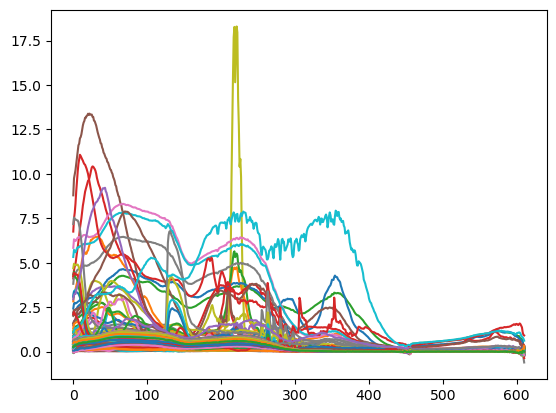

In [20]:
for i in range(113):
    plt.plot(x[i])

In [21]:
clf = LogisticRegression(random_state=0).fit(x_, y)
clf.score(x_, y)

0.9734513274336283

In [22]:
# construct folds: -----------------------------------------------------------
n = y.shape[0]

x = df_spectra.iloc[:,:-1].to_numpy()
y = df_spectra.iloc[:,-1].to_numpy()

idx = sample(range(n), n)
df_spectra_ = df_spectra.copy()
df_spectra['fold'] = np.array(idx) // (n/10)
folds_size = pd.DataFrame(df_spectra.groupby('fold').size())
folds_size.columns = ['Size']

# folds as array indices
folds = []

rows = np.arange(n)
for fold in range(10):
    train = np.asarray(df_spectra['fold'] != fold).nonzero()[0]
    test = np.asarray(df_spectra['fold'] == fold).nonzero()[0]
    folds.append((train, test))

## Logistic Regression

In [23]:
metrics = defaultdict(list)
#.fit(x, y)
C = np.linspace(0,1,10)
for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x[val, :]
    y_v = y[val]
            
    for i in range(1):
        # track current 
        metrics['fold'].append(fold)
        #metrics['c'].append(c)
        
        # train model
        clf = LogisticRegression(random_state=0,)#, C=c)
        clf.fit(x_in, y_in)            
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics['acc_train'].append(clf.score(x_in, y_in))
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics['acc_val'].append(clf.score(x_v, y_v))
                
        metrics['n'].append(len(y_v))
        
        #print(fold)
        
metrics_df = pd.DataFrame(metrics)

### Normalized Spectra

In [24]:
logreg_norm_acc_val = metrics_df.mean()['acc_val']
logreg_norm_acc_val

0.9015151515151516

### Unormalized Spectra

In [25]:
logreg_un_acc_val = metrics_df.mean()['acc_val']
logreg_un_acc_val

0.9015151515151516

## K means

In [27]:
x_in.shape

(102, 611)

In [20]:
metrics_kmeans = defaultdict(list)
#.fit(x, y)
C = np.linspace(0,1,10)
for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x_[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x_[val, :]
    y_v = y[val]
            
    for k in np.arange(2, x_in.shape[0], 10):
        # track current 
        metrics_kmeans['fold'].append(fold)
        metrics_kmeans['k'].append(k)
        
        # train model
        kmeans = KMeans(n_clusters=k, random_state=0).fit(x_in)
        bg_label = stats.mode(kmeans.labels_[y_in == 1]).mode[0]
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics_kmeans['acc_train'].append(((kmeans.labels_ == bg_label) * 1 == y_in).mean())
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics_kmeans['acc_val'].append(((kmeans.predict(x_v) == bg_label) * 1 == y_v).mean())
                
        metrics_kmeans['n'].append(len(y_v))
        
        #print(fold)
        
metrics_kmeans_df = pd.DataFrame(metrics_kmeans)
#metrics_df#.mean()#.groupby('c').mean()#
metrics_kmeans_df.groupby('k').mean()

,fold,acc_train,acc_val,n
k,,,,
2,4.5,0.560241,0.549242,11.3
12,4.5,0.808270,0.805303,11.3
22,4.5,0.848525,0.805303,11.3
32,4.5,0.901611,0.856818,11.3
42,4.5,0.898758,0.875758,11.3
52,4.5,0.929247,0.937879,11.3
62,4.5,0.805310,0.798485,11.3
72,4.5,0.774888,0.796212,11.3
82,4.5,0.741419,0.737879,11.3


In [51]:
kmean_norm_acc_val = (metrics_kmeans_df.groupby('k').mean()['acc_val']).max()
kmean_norm_acc_val

0.9378787878787879

In [25]:
(metrics_kmeans_df.groupby('k').mean()['acc_val'])[5:6]

k
52    0.937879
Name: acc_val, dtype: float64

In [26]:
import statsmodels.api as sm

In [38]:
lowess = sm.nonparametric.lowess
x_k = metrics_kmeans_df.groupby('k').mean().index.to_numpy()
y_val = metrics_kmeans_df.groupby('k').mean()['acc_val'].to_numpy()
y_train = metrics_kmeans_df.groupby('k').mean()['acc_train'].to_numpy()
z_val = lowess(y_val, x_k, frac=.1)
z_train = lowess(y_train, x_k, frac=.1)

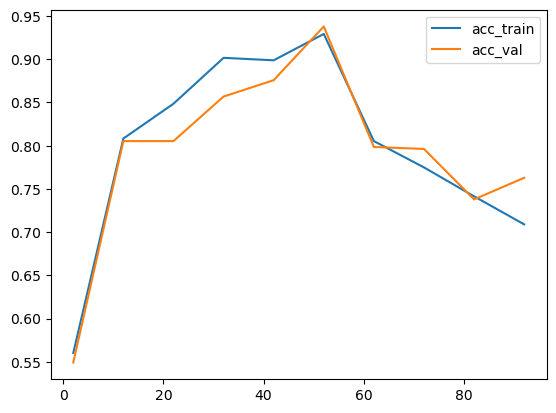

In [39]:
#plt.plot(x, y)
#plt.plot(metrics_kmeans_df.groupby('k').mean()['acc_train'])
#plt.plot(metrics_kmeans_df.groupby('k').mean()['acc_val'])
plt.plot(z_train[:,0], z_train[:,1], label='acc_train')
plt.plot(z_val[:,0], z_val[:,1], label='acc_val')
plt.legend()

In [42]:
metrics_kmeans_un = defaultdict(list)
#.fit(x, y)
C = np.linspace(0,1,10)
for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x[val, :]
    y_v = y[val]
            
    for k in np.arange(2, x_in.shape[0], 10):
        # track current 
        metrics_kmeans_un['fold'].append(fold)
        metrics_kmeans_un['k'].append(k)
        
        # train model
        kmeans = KMeans(n_clusters=k, random_state=0).fit(x_in)
        bg_label = stats.mode(kmeans.labels_[y_in == 1]).mode[0]
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics_kmeans_un['acc_train'].append(((kmeans.labels_ == bg_label) * 1 == y_in).mean())
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics_kmeans_un['acc_val'].append(((kmeans.predict(x_v) == bg_label) * 1 == y_v).mean())
                
        metrics_kmeans_un['n'].append(len(y_v))
        
        #print(fold)
        
metrics_kmeans_un_df = pd.DataFrame(metrics_kmeans_un)
#metrics_df#.mean()#.groupby('c').mean()#
metrics_kmeans_un_df.groupby('k').mean()

,fold,acc_train,acc_val,n
k,,,,
2,4.5,0.424762,0.423485,11.3
12,4.5,0.775849,0.762879,11.3
22,4.5,0.784644,0.748485,11.3
32,4.5,0.789614,0.787121,11.3
42,4.5,0.765017,0.698485,11.3
52,4.5,0.772869,0.743182,11.3
62,4.5,0.763056,0.759848,11.3
72,4.5,0.735517,0.727273,11.3
82,4.5,0.712920,0.675000,11.3


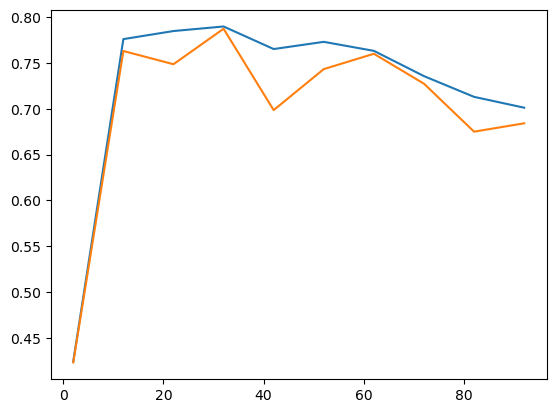

In [44]:
plt.plot(metrics_kmeans_un_df.groupby('k').mean()['acc_train'])
plt.plot(metrics_kmeans_un_df.groupby('k').mean()['acc_val'])

In [50]:
kmean_un_acc_val = (metrics_kmeans_un_df.groupby('k').mean()['acc_val']).max()
kmean_un_acc_val

In [49]:
(metrics_kmeans_un_df.groupby('k').mean()['acc_val'])[3:4]

k
32    0.787121
Name: acc_val, dtype: float64

## Random Forest

In [56]:
clf = RandomForestClassifier(max_depth=2, random_state=0)
clf.fit(x_, y)
clf.score(x_,y)

0.9734513274336283

In [63]:
metrics_rf = defaultdict(list)
#.fit(x, y)

for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x_[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x_[val, :]
    y_v = y[val]
            
    for ne in np.arange(100, 1000, 100):
        # track current 
        metrics_rf['fold'].append(fold)
        metrics_rf['ne'].append(ne)
        
        # train model
        clf = RandomForestClassifier(max_depth=2, n_estimators=ne, random_state=0)
        clf.fit(x_in, y_in)            
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics_rf['acc_train'].append(clf.score(x_in, y_in))
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics_rf['acc_val'].append(clf.score(x_v, y_v))
                
        metrics_rf['n'].append(len(y_v))
        
        #print(fold)
        
metrics_rf_df = pd.DataFrame(metrics_rf)
#metrics_df#.mean()#.groupby('c').mean()#

In [64]:
rf_norm_acc_val = metrics_rf_df.groupby('ne').mean().max()['acc_val']
rf_norm_acc_val

0.9393939393939394

In [62]:
rf_un_acc_val = metrics_rf_df.groupby('ne').mean().max()['acc_val']
rf_un_acc_val

0.9287878787878787

## SVM

In [66]:
#clf = make_pipeline(StandardScaler(), SVC(gamma='auto'))
clf = SVC(gamma='auto')
clf.fit(x, y)
clf.score(x, y)

0.8584070796460177

In [80]:
metrics_svm = defaultdict(list)
#.fit(x, y)

for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x_[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x_[val, :]
    y_v = y[val]
            
    for c in np.linspace(0.1,100,20):
        # track current 
        metrics_svm['fold'].append(fold)
        metrics_svm['c'].append(c)
        
        # train model
        clf = SVC(gamma='auto', C=c)
        clf.fit(x_in, y_in)            
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics_svm['acc_train'].append(clf.score(x_in, y_in))
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics_svm['acc_val'].append(clf.score(x_v, y_v))
                
        metrics_svm['n'].append(len(y_v))
        
        #print(fold)
        
metrics_svm_df = pd.DataFrame(metrics_svm)
metrics_svm_df.groupby('c').mean()#.mean()##


,fold,acc_train,acc_val,n
c,,,,
0.100000,4.5,0.672607,0.675758,11.3
5.357895,4.5,0.906601,0.859091,11.3
10.615789,4.5,0.934110,0.885606,11.3
15.873684,4.5,0.944923,0.893939,11.3
21.131579,4.5,0.960648,0.893939,11.3
26.389474,4.5,0.970481,0.928030,11.3
31.647368,4.5,0.971472,0.936364,11.3
36.905263,4.5,0.972462,0.945455,11.3
42.163158,4.5,0.973442,0.945455,11.3


In [81]:
svm_norm_acc_val = metrics_svm_df.groupby('c').mean().max()['acc_val']
svm_norm_acc_val

0.9454545454545455

In [79]:
svm_un_acc_val = metrics_svm_df.groupby('c').mean().max()['acc_val']
svm_un_acc_val

0.9022727272727273

In [89]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(x_, y)

print(neigh.score(x_,y))


0.9469026548672567


In [111]:
metrics_knn = defaultdict(list)
#.fit(x, y)

for fold, (train, val) in enumerate(folds):
    
    # training data
    x_in = x_[train, :]
    y_in = y[train]
    n, p = x_in.shape
            
    # validation data
    x_v = x_[val, :]
    y_v = y[val]
            
    for k in range(2,3):
        # track current 
        metrics_knn['fold'].append(fold)
        metrics_knn['k'].append(k)
        
        # train model
        clf = KNeighborsClassifier(n_neighbors=k)
        clf.fit(x_in, y_in)            
                
        # record training fit 
        #y_hat = res_rf.predict(x_in)
                
        metrics_knn['acc_train'].append(clf.score(x_in, y_in))
                
        # make predictions on validation data
        #y_hat = res_rf.predict(x_v)
                
        # evaluate predictions
        metrics_knn['acc_val'].append(clf.score(x_v, y_v))
                
        metrics_knn['n'].append(len(y_v))
        
        #print(fold)
        
metrics_knn_df = pd.DataFrame(metrics_knn)
metrics_knn_df.groupby('k').mean()#.mean()##


,fold,acc_train,acc_val,n
k,,,,
2,4.5,0.975422,0.912879,11.3


In [112]:
knn_norm_acc_val = metrics_knn_df.groupby('k').mean()['acc_val'][2]
knn_norm_acc_val

0.9128787878787878

In [110]:
knn_un_acc_val = metrics_knn_df.groupby('k').mean()['acc_val'][2]
knn_un_acc_val

0.9037878787878789

In [116]:
pd.DataFrame(
    {
    'model': [
        'Logistic Regression', 'K mean cluster', 'Random Forest', 'SVM', 'KNN'],
    'validation_accuracy_norm': [
        logreg_norm_acc_val,
        kmean_norm_acc_val,
        rf_norm_acc_val,
        svm_norm_acc_val,
        knn_norm_acc_val],
    'validation_accuracy': [
        logreg_un_acc_val,
        kmean_un_acc_val,
        rf_un_acc_val,
        svm_un_acc_val,
        knn_un_acc_val]
    }
).sort_values('validation_accuracy_norm', ascending=False)

,model,validation_accuracy_norm,validation_accuracy
3,SVM,0.945455,0.902273
2,Random Forest,0.939394,0.928788
1,K mean cluster,0.937879,0.787121
0,Logistic Regression,0.928788,0.893182
4,KNN,0.912879,0.903788


In [383]:
spectra_data = pd.read_csv('/Users/eochoa/Downloads/MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1_background_test.csv')
del spectra_data['X value [cm⁻¹]']
spectra_data #= spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])].iloc[:-2,:]#.to_numpy()

,948,950,952,954,956,958,960,962,964,966,...,2988,2990,2992,2994,2996,2998,3000,3002,3004,Unnamed: 1030
0,-0.003740,-0.002088,-0.002649,-0.001558,-0.002256,-0.001852,-0.002011,-0.001667,-0.001355,-0.000906,...,-0.003340,-0.005161,-0.002737,-0.003246,-0.004476,-0.008992,-0.007812,-0.012369,-0.012640,NaN
1,2154.498143,2745.894599,3378.368710,4003.493814,4606.671137,5233.478150,5948.732432,6796.996749,7778.951840,8852.868050,...,2169.591680,1930.633734,1700.826397,1452.120414,1236.737407,1023.827208,822.223883,735.135327,735.135327,NaN
2,0.242102,0.190836,0.328645,0.422800,-0.024640,-0.074862,0.076131,-0.026117,0.123493,0.054350,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2154.498143,2745.894599,3378.368710,4003.493814,4606.671137,5233.478150,5948.732432,6796.996749,7778.951840,8852.868050,...,2169.591680,1930.633734,1700.826397,1452.120414,1236.737407,1023.827208,822.223883,735.135327,735.135327,NaN
4,-0.687912,-0.081952,-0.072394,-0.191014,-0.180399,-0.087266,-0.065331,-0.063950,-0.100001,-0.093635,...,-0.134641,-0.310853,-0.323163,-0.204217,-0.218061,-0.267938,-0.110596,-0.325126,-0.534448,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
348,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,...,65535.000000,65535.000000,65535.000000,65535.000000,NaN,NaN,NaN,NaN,NaN,NaN
349,15976.000000,16047.553711,16169.431641,16218.968750,16188.429688,16233.456055,16370.284180,16499.726562,16617.349609,16703.585938,...,17037.695312,16967.656250,16956.320312,16756.000000,NaN,NaN,NaN,NaN,NaN,NaN
350,65535.000000,65535.000000,65535.000000,54219.500000,29543.685547,1579.777344,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [367]:
np.isnan(spectra_data.iloc[0,:]).sum()

419

In [385]:
#spectra_data.sum(1)
spectra_data = spectra_data.loc[np.isnan(spectra_data.sum(axis=1, skipna=False)), :]#[np.isnan(spectra_data)] = 0
spectra_data.shape

(353, 1030)

In [369]:
spectra_data_long = spectra_data.reset_index().melt(
    id_vars='index',
    #value_vars='',
    var_name='wavelength',
    value_name='intensity'
)
spectra_data_long.columns = ['file_name'] + list(spectra_data_long.columns[1:])
spectra_data_long['polymer'] = ''
spectra_data_long = spectra_data_long.query('intensity == intensity')
spectra_data_long['wavelength'] = spectra_data_long['wavelength'].astype('float32')#.min()
spectra_data_long.sort_values(['file_name', 'wavelength'])

,file_name,wavelength,intensity,polymer
0,0,948.0,-0.003740,
353,0,950.0,-0.002088,
706,0,952.0,-0.002649,
1059,0,954.0,-0.001558,
1412,0,956.0,-0.002256,
...,...,...,...,...
360057,350,2986.0,0.000000,
360410,350,2988.0,0.000000,
360763,350,2990.0,0.000000,
361116,350,2992.0,0.000000,


In [370]:
np.linspace(948, 3004, num=1029, endpoint=True)

array([ 948.,  950.,  952., ..., 3000., 3002., 3004.])

In [371]:
spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=948, max_wl=3004,n=1029)

In [372]:
spectra_data_long_int

,wavelength,intensity,polymer,file_name
0,948.0,-0.003740,,0
1,950.0,-0.002088,,0
2,952.0,-0.002649,,0
3,954.0,-0.001558,,0
4,956.0,-0.002256,,0
...,...,...,...,...
361174,2996.0,0.000000,,350
361175,2998.0,0.000000,,350
361176,3000.0,0.000000,,350
361177,3002.0,0.000000,,350


In [373]:
spectra_data_int = spectra_data_long_int.pivot(index='file_name', columns='wavelength', values='intensity')

In [374]:
spectra_data_int#.shape

wavelength,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2986.0,2988.0,2990.0,2992.0,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0
file_name,,,,,,,,,,,,,,,,,,,,,
0,-0.003740,-0.002088,-0.002649,-0.001558,-0.002256,-0.001852,-0.002011,-0.001667,-0.001355,-0.000906,...,-0.003306,-0.003340,-0.005161,-0.002737,-0.003246,-0.004476,-0.008992,-0.007812,-0.012369,-0.012640
1,2154.498143,2745.894599,3378.368710,4003.493814,4606.671137,5233.478150,5948.732432,6796.996749,7778.951840,8852.868050,...,2423.956830,2169.591680,1930.633734,1700.826397,1452.120414,1236.737407,1023.827208,822.223883,735.135327,735.135327
2,0.242102,0.190836,0.328645,0.422800,-0.024640,-0.074862,0.076131,-0.026117,0.123493,0.054350,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,2154.498143,2745.894599,3378.368710,4003.493814,4606.671137,5233.478150,5948.732432,6796.996749,7778.951840,8852.868050,...,2423.956830,2169.591680,1930.633734,1700.826397,1452.120414,1236.737407,1023.827208,822.223883,735.135327,735.135327
4,-0.687912,-0.081952,-0.072394,-0.191014,-0.180399,-0.087266,-0.065331,-0.063950,-0.100001,-0.093635,...,-0.098853,-0.134641,-0.310853,-0.323163,-0.204217,-0.218061,-0.267938,-0.110596,-0.325126,-0.534448
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,65535.000000,65535.000000,65535.000000,54284.085938,29687.230469,1587.453125,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
347,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
348,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,...,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [375]:
spectra_data_int.to_numpy()

array([[-3.73961846e-03, -2.08761450e-03, -2.64930609e-03, ...,
        -7.81240733e-03, -1.23690050e-02, -1.26401028e-02],
       [ 2.15449814e+03,  2.74589460e+03,  3.37836871e+03, ...,
         8.22223883e+02,  7.35135327e+02,  7.35135327e+02],
       [ 2.42101595e-01,  1.90835714e-01,  3.28644693e-01, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 6.55350000e+04,  6.55350000e+04,  6.55350000e+04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.59760000e+04,  1.60475537e+04,  1.61694316e+04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 6.55350000e+04,  6.55350000e+04,  6.55350000e+04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

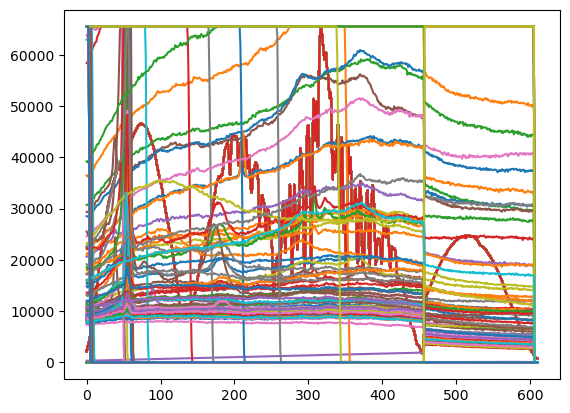

In [377]:
_ = plt.plot(spectra_data_int.to_numpy()[:,~np.isnan(spectra_data.iloc[0,:-1])].T)

In [378]:
spectra_data = (spectra_data - np.nanmean(spectra_data, 1)[:,None]) / np.nanstd(spectra_data, 1)[:,None]

In [388]:
np.isnan(spectra_data).sum(1)

0       419
1       420
2       534
3       420
4       419
       ... 
348       6
349       6
350       6
351    1030
352    1030
Length: 353, dtype: int64

In [387]:
spectra_data[np.isnan(spectra_data).sum(1) == 2, :].sum(0)

InvalidIndexError: (0      False
1      False
2      False
3      False
4      False
       ...  
348    False
349    False
350    False
351    False
352    False
Length: 353, dtype: bool, slice(None, None, None))

In [386]:
_ = plt.plot(spectra_data[np.isnan(spectra_data).sum(1) == 2, :].T)
#_ = plt.plot(spectra_data[1,:].T)

InvalidIndexError: (0      False
1      False
2      False
3      False
4      False
       ...  
348    False
349    False
350    False
351    False
352    False
Length: 353, dtype: bool, slice(None, None, None))

In [149]:
spectra_data

array([[-2.9392775 , -1.82998651, -2.20715232, ..., -5.67408206,
        -8.73375555, -8.91579282],
       [-9.43819624, -1.18830942, -1.05816822, ..., -1.57828496,
        -4.49901612, -7.34884788],
       [-0.12138265, -0.3045343 ,  0.10042087, ..., -0.40181655,
        -0.34833729, -0.87207759],
       ...,
       [ 4.76701914,  0.50525925, -1.71175213, ...,  2.35714647,
        -4.9387577 , 13.24096894],
       [ 2.50567383,  3.3041479 ,  2.57078735, ...,  7.39423764,
        14.33626611, 13.88122374],
       [ 1.67786803, -3.90950248, -1.45210986, ...,  9.07017228,
         2.49263508, -4.89397627]])

In [158]:
kmeans = KMeans(n_clusters=2, random_state=0).fit(spectra_data)
#bg_label = stats.mode(kmeans.labels_[y_in == 1]).mode[0]


In [159]:
labels = kmeans.predict(spectra_data)

In [160]:
labels

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1], dtype=int32)

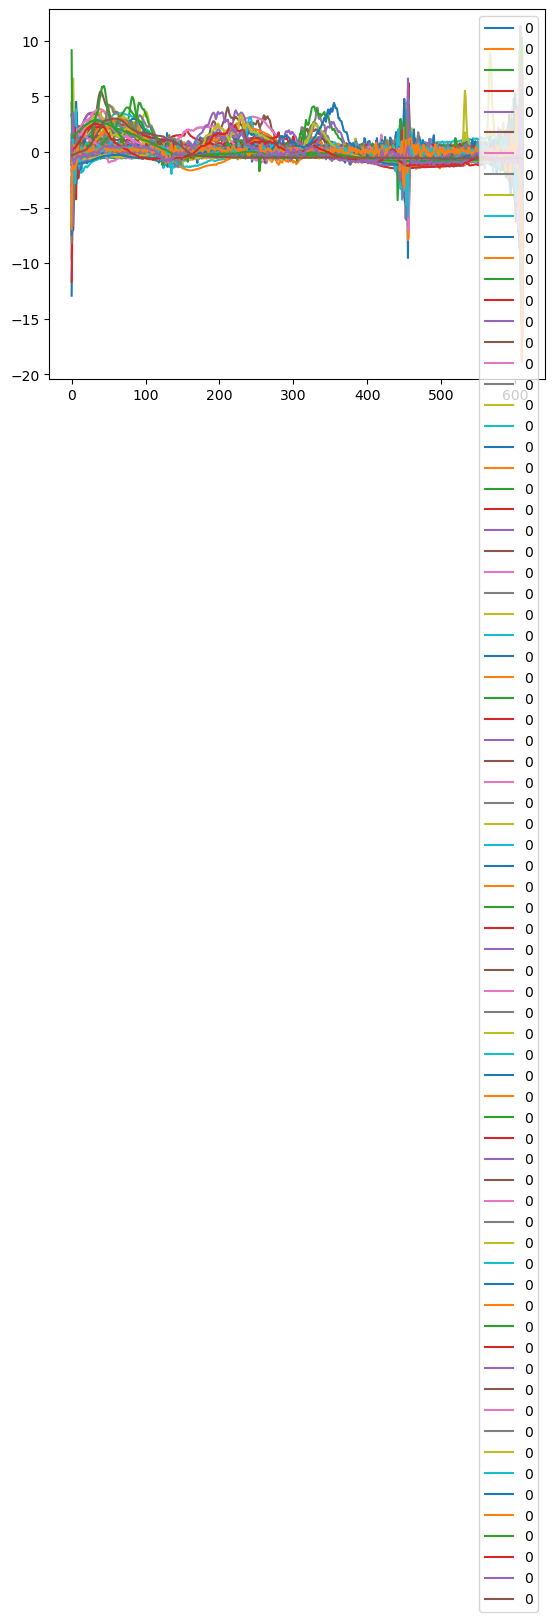

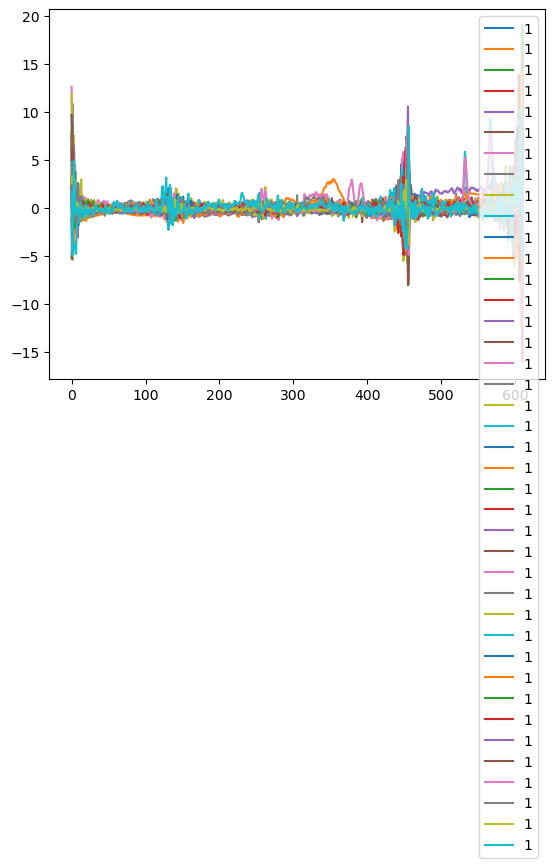

In [161]:
for l in np.unique(labels):
    _ = plt.plot(spectra_data[labels == l, :].T, label = l)
    _ = plt.legend()
    _ = plt.show()
